In [1]:
import numpy as np 
import pandas as pd
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shubh0799/churn-modelling/Churn_Modelling.csv


In [2]:
path = "/kaggle/input/datasets/shubh0799/churn-modelling/Churn_Modelling.csv"

In [3]:
df = pd.read_csv(path)
print(df.shape) # 10000 rows and 14 features

print(df.isnull().sum())
print("Total Duplicates:", df.duplicated().sum())
df.describe()

(10000, 14)
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Total Duplicates: 0


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [4]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

X = df.drop(columns=['Exited', 'RowNumber', 'CustomerId', 'Surname'])
y = df['Exited']

X = pd.get_dummies(X, drop_first=True)

mi = mutual_info_classif(X, y, random_state=42)

mi_scores = pd.Series(mi, index=X.columns)
mi_scores = mi_scores.sort_values(ascending=False)

print(mi_scores)

Age                  0.073233
NumOfProducts        0.068655
IsActiveMember       0.016044
Geography_Germany    0.015273
Balance              0.011387
Gender_Male          0.005136
EstimatedSalary      0.002709
Geography_Spain      0.001872
Tenure               0.001335
CreditScore          0.000000
HasCrCard            0.000000
dtype: float64


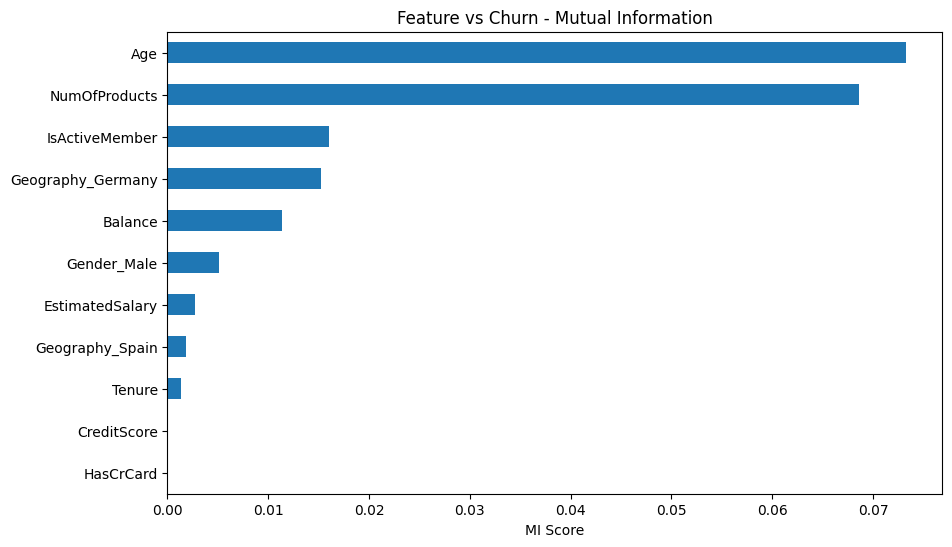

In [5]:
import matplotlib.pyplot as plt

mi_scores.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title("Feature vs Churn - Mutual Information")
plt.xlabel("MI Score")
plt.show()

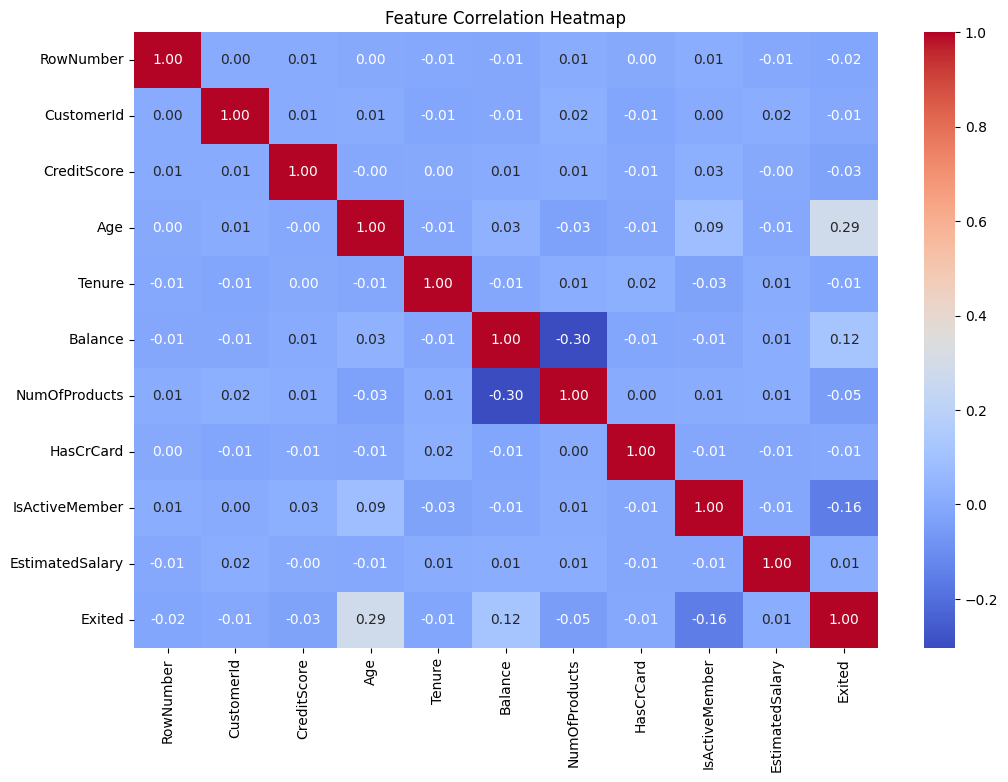

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [7]:
print(X.shape)
print(y.shape)

(10000, 11)
(10000,)


In [32]:
import torch 
import torch.nn as nn

class CustomerNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(11,128)
        self.relu1 = nn.ReLU()
        self.layer2 = nn.Linear(128,64)
        self.relu2 = nn.ReLU()
        self.layer3 = nn.Linear(64,32)
        self.relu3 = nn.ReLU()
        self.output = nn.Linear(32,1)
        self.sigmoid = nn.Sigmoid()

    def forward(self,x):
        x = self.layer1(x)
        x = self.relu1(x)
        x = self.layer2(x)
        x = self.relu2(x)
        x = self.layer3(x)
        x = self.relu3(x)
        x = self.output(x)
        x = self.sigmoid(x)
        return x

In [9]:
# Convert True/False to 1/0
X = X.astype('float32')
y = y.astype('float32')

# Convert to tensors
X = torch.tensor(X.values, dtype=torch.float32)
y = torch.tensor(y.values, dtype=torch.float32).reshape(-1, 1)

print(X.shape)
print(y.shape)

torch.Size([10000, 11])
torch.Size([10000, 1])


In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [11]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [33]:
model = CustomerNet().to(device)
print(model)

CustomerNet(
  (layer1): Linear(in_features=11, out_features=128, bias=True)
  (relu1): ReLU()
  (layer2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (layer3): Linear(in_features=64, out_features=32, bias=True)
  (relu3): ReLU()
  (output): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [16]:
from torch.utils.data import TensorDataset, DataLoader

# 1. Convert all data into tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)


# 2. Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)


# 3. Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False
)


# 4. Verify
print("Train Dataset:", len(train_dataset))
print("Test Dataset:", len(test_dataset))

print("Train Batches:", len(train_loader))
print("Test Batches:", len(test_loader))

Train Dataset: 8000
Test Dataset: 2000
Train Batches: 8
Test Batches: 2


/tmp/ipykernel_50/908620649.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
/tmp/ipykernel_50/908620649.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)


In [28]:
criterion = nn.BCELoss()
epochs = 50

lr = 0.01

loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for batch_x , batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        output = model(batch_x)
        loss = criterion(output,batch_y)

        loss.backward()

        with torch.no_grad():
            for param in model.parameters():
                if param.grad is not None:
                    param.data -= lr * param.grad  
                    param.grad.zero_()   
        total_loss += loss.item()

    epoch_loss = total_loss / len(train_loader)
    loss_history.append(epoch_loss)
    print(f"Epoch [{epoch+1}/{epochs}] Loss: {epoch_loss:.4f}")
    

Epoch [1/50] Loss: 0.7111
Epoch [2/50] Loss: 0.6997
Epoch [3/50] Loss: 0.6891
Epoch [4/50] Loss: 0.6790
Epoch [5/50] Loss: 0.6694
Epoch [6/50] Loss: 0.6604
Epoch [7/50] Loss: 0.6517
Epoch [8/50] Loss: 0.6435
Epoch [9/50] Loss: 0.6359
Epoch [10/50] Loss: 0.6280
Epoch [11/50] Loss: 0.6212
Epoch [12/50] Loss: 0.6143
Epoch [13/50] Loss: 0.6078
Epoch [14/50] Loss: 0.6016
Epoch [15/50] Loss: 0.5957
Epoch [16/50] Loss: 0.5899
Epoch [17/50] Loss: 0.5845
Epoch [18/50] Loss: 0.5792
Epoch [19/50] Loss: 0.5743
Epoch [20/50] Loss: 0.5696
Epoch [21/50] Loss: 0.5651
Epoch [22/50] Loss: 0.5605
Epoch [23/50] Loss: 0.5570
Epoch [24/50] Loss: 0.5530
Epoch [25/50] Loss: 0.5493
Epoch [26/50] Loss: 0.5458
Epoch [27/50] Loss: 0.5427
Epoch [28/50] Loss: 0.5395
Epoch [29/50] Loss: 0.5367
Epoch [30/50] Loss: 0.5338
Epoch [31/50] Loss: 0.5314
Epoch [32/50] Loss: 0.5288
Epoch [33/50] Loss: 0.5266
Epoch [34/50] Loss: 0.5246
Epoch [35/50] Loss: 0.5226
Epoch [36/50] Loss: 0.5210
Epoch [37/50] Loss: 0.5191
Epoch [38/

In [34]:
criterion = nn.BCELoss()
epochs = 50

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()               
        output = model(batch_x)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()                    

        total_loss += loss.item()

    epoch_loss = total_loss / len(train_loader)
    loss_history.append(epoch_loss)
    print(f"Epoch [{epoch+1}/{epochs}] Loss: {epoch_loss:.4f}")

Epoch [1/50] Loss: 0.6185
Epoch [2/50] Loss: 0.5664
Epoch [3/50] Loss: 0.5156
Epoch [4/50] Loss: 0.4948
Epoch [5/50] Loss: 0.4720
Epoch [6/50] Loss: 0.4541
Epoch [7/50] Loss: 0.4417
Epoch [8/50] Loss: 0.4308
Epoch [9/50] Loss: 0.4252
Epoch [10/50] Loss: 0.4213
Epoch [11/50] Loss: 0.4167
Epoch [12/50] Loss: 0.4103
Epoch [13/50] Loss: 0.4032
Epoch [14/50] Loss: 0.3928
Epoch [15/50] Loss: 0.3825
Epoch [16/50] Loss: 0.3708
Epoch [17/50] Loss: 0.3605
Epoch [18/50] Loss: 0.3519
Epoch [19/50] Loss: 0.3444
Epoch [20/50] Loss: 0.3405
Epoch [21/50] Loss: 0.3368
Epoch [22/50] Loss: 0.3356
Epoch [23/50] Loss: 0.3328
Epoch [24/50] Loss: 0.3300
Epoch [25/50] Loss: 0.3287
Epoch [26/50] Loss: 0.3293
Epoch [27/50] Loss: 0.3295
Epoch [28/50] Loss: 0.3253
Epoch [29/50] Loss: 0.3222
Epoch [30/50] Loss: 0.3220
Epoch [31/50] Loss: 0.3199
Epoch [32/50] Loss: 0.3184
Epoch [33/50] Loss: 0.3176
Epoch [34/50] Loss: 0.3178
Epoch [35/50] Loss: 0.3154
Epoch [36/50] Loss: 0.3134
Epoch [37/50] Loss: 0.3125
Epoch [38/

In [36]:
from sklearn.metrics import roc_auc_score, classification_report

model.eval()
with torch.no_grad():
    probs = model(X_test.to(device)).cpu().numpy().flatten()
    preds = (probs > 0.5).astype(int)

print("AUC:", roc_auc_score(y_test, probs))
print(classification_report(y_test, preds))

AUC: 0.8548440582338886
              precision    recall  f1-score   support

         0.0       0.88      0.96      0.92      1593
         1.0       0.77      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000



In [37]:
import torch
from sklearn.metrics import roc_auc_score, classification_report, accuracy_score

model.eval()

test_loss = 0
all_probs = []
all_preds = []
all_labels = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        out = model(batch_x)
        loss = criterion(out, batch_y)
        test_loss += loss.item()

        probs = out.cpu().numpy().flatten()
        preds = (probs > 0.5).astype(int)
        labels = batch_y.cpu().numpy().flatten().astype(int)

        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(labels)

avg_test_loss = test_loss / len(test_loader)
acc = accuracy_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)

print(f"Test Loss : {avg_test_loss:.4f}")
print(f"Accuracy  : {acc:.4f}")
print(f"AUC       : {auc:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds))

Test Loss : 0.3444
Accuracy  : 0.8620
AUC       : 0.8548

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.77      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000

